# imports models

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.model_selection import KFold

# Metrics
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, f1_score
)
# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)





# Data Cleaning 

In [2]:
data = pd.read_csv('Titanic-Dataset.csv')

In [3]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
data.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
#delete cabin due its high number of missing values
#delete name , has no effect on the survival of the passengers , has no meaningful information for the model

data.drop('Cabin', axis=1, inplace=True)
data.drop('Name', axis=1, inplace=True)

In [7]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked'],
      dtype='str')

In [8]:
#delete all rows with missing values of age and embarked columns
data.dropna(subset=['Age', 'Embarked'], inplace=True)

In [9]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked'],
      dtype='str')

In [10]:
#now the data are clean and ready for analysis, age, Cabin and Embarked can not be filled with mean or median values
#so we will delete the rows with missing values.
data.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Sex          712 non-null    str    
 4   Age          712 non-null    float64
 5   SibSp        712 non-null    int64  
 6   Parch        712 non-null    int64  
 7   Ticket       712 non-null    str    
 8   Fare         712 non-null    float64
 9   Embarked     712 non-null    str    
dtypes: float64(2), int64(5), str(3)
memory usage: 70.2 KB


In [11]:
data.head(10)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,female,35.0,1,0,113803,53.1000,S
4,5,0,3,male,35.0,0,0,373450,8.0500,S
6,7,0,1,male,54.0,0,0,17463,51.8625,S
7,8,0,3,male,2.0,3,1,349909,21.0750,S
8,9,1,3,female,27.0,0,2,347742,11.1333,S
9,10,1,2,female,14.0,1,0,237736,30.0708,C
10,11,1,3,female,4.0,1,1,PP 9549,16.7000,S


In [12]:
ndata= data.copy()

In [13]:
ndata.head(20)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,female,35.0,1,0,113803,53.1000,S
4,5,0,3,male,35.0,0,0,373450,8.0500,S
6,7,0,1,male,54.0,0,0,17463,51.8625,S
7,8,0,3,male,2.0,3,1,349909,21.0750,S
8,9,1,3,female,27.0,0,2,347742,11.1333,S
9,10,1,2,female,14.0,1,0,237736,30.0708,C
10,11,1,3,female,4.0,1,1,PP 9549,16.7000,S


# Exploratory Data Analysis-EDA 

In [14]:
ndata.head()
ndata.info()
ndata.describe()
ndata.shape
ndata.isnull().sum()   

<class 'pandas.DataFrame'>
Index: 712 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Sex          712 non-null    str    
 4   Age          712 non-null    float64
 5   SibSp        712 non-null    int64  
 6   Parch        712 non-null    int64  
 7   Ticket       712 non-null    str    
 8   Fare         712 non-null    float64
 9   Embarked     712 non-null    str    
dtypes: float64(2), int64(5), str(3)
memory usage: 70.2 KB


PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

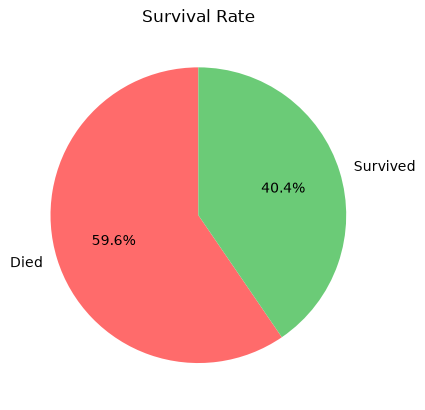

In [15]:
import seaborn as sns


# Pie chart
ndata ['Survived'].value_counts().plot.pie(
    autopct='%1.1f%%', labels=['Died', 'Survived'],
    colors=['#ff6b6b', '#6bcb77'], startangle=90
)
plt.title('Survival Rate')
plt.ylabel('')
plt.show()

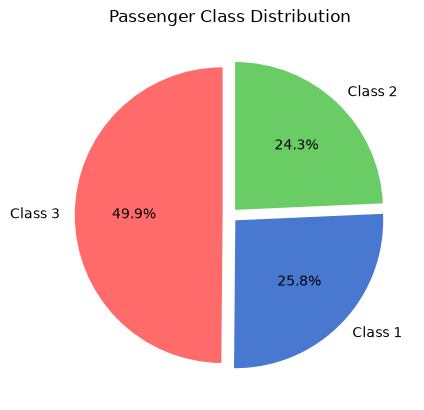

In [16]:
ndata['Pclass'].value_counts().plot.pie(
    autopct='%1.1f%%',
    labels=['Class 3', 'Class 1', 'Class 2'],
    colors=['#ff6b6b', '#4878cf', '#6acc65'],
    startangle=90,
    explode=(0.05, 0.05, 0.05)
)
plt.title('Passenger Class Distribution')
plt.ylabel('')
plt.show()

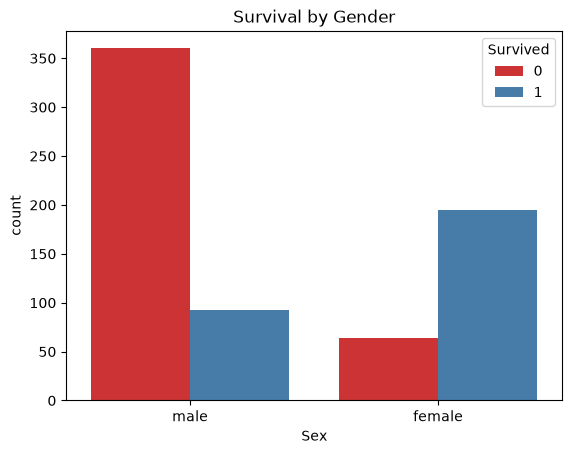

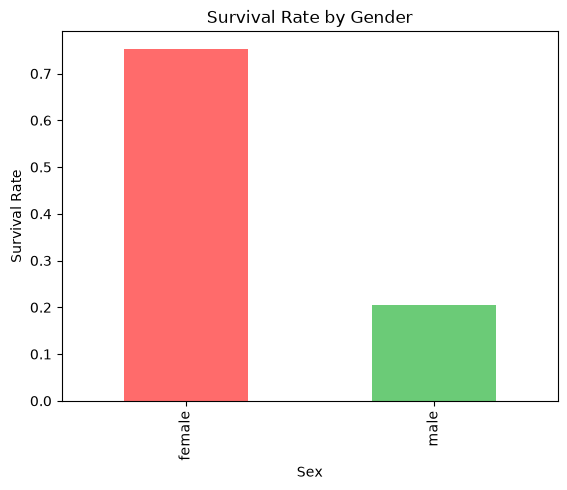

In [17]:
sns.countplot(x='Sex', hue='Survived', data=ndata, palette='Set1')
plt.title('Survival by Gender')
plt.show()

# Survival rate
ndata.groupby('Sex')['Survived'].mean().plot(kind='bar', color=['#ff6b6b', '#6bcb77'])
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.show()

In [18]:
# the people were sacrificed in the accident, and the women and children were given priority to be saved, 
# so the survival rate of women is higher than men.

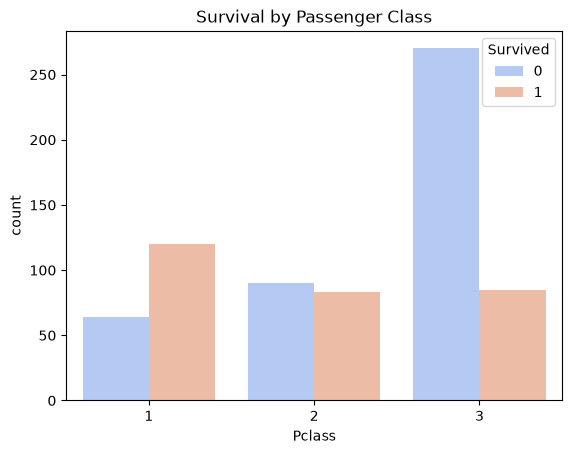

In [19]:
sns.countplot(x='Pclass', hue='Survived', data=ndata, palette='coolwarm')
plt.title('Survival by Passenger Class')
plt.show()

In [20]:
#as we see the survival rate is higher in the first class and lower in the third class, 
# this is because the first class passengers had better access to lifeboats
# and were given priority during the evacuation process.
# In contrast, third class passengers were often located in lower decks and had limited access to lifeboats, resulting in a lower survival rate.

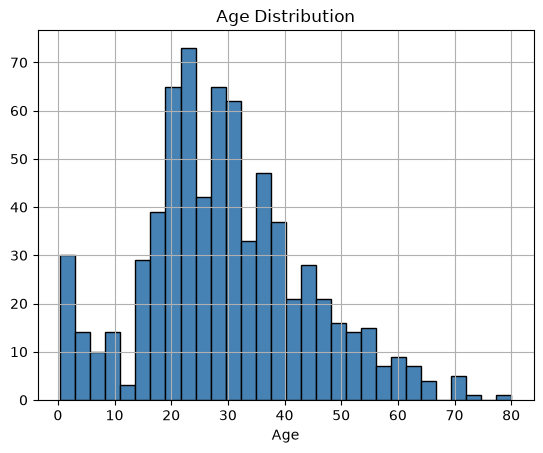

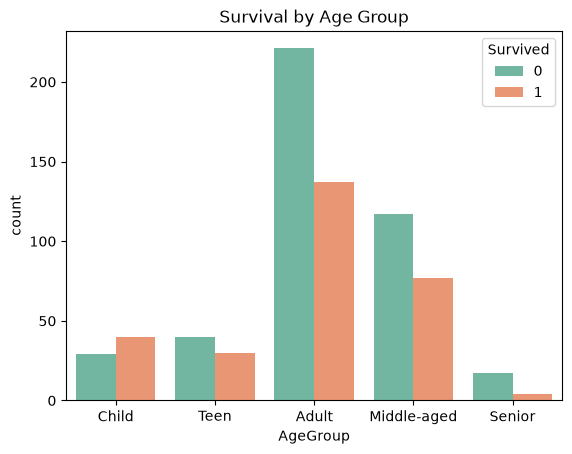

In [21]:
# Age distribution
ndata['Age'].hist(bins=30, edgecolor='black', color='steelblue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()



# Age bins + survival
ndata['AgeGroup'] = pd.cut(ndata['Age'], bins=[0,12,18,35,60,100],
                            labels=['Child','Teen','Adult','Middle-aged','Senior'])
sns.countplot(x='AgeGroup', hue='Survived', data=ndata, palette='Set2')
plt.title('Survival by Age Group')
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_42904\436234330.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Survived', y='Fare', data=ndata, palette='coolwarm')


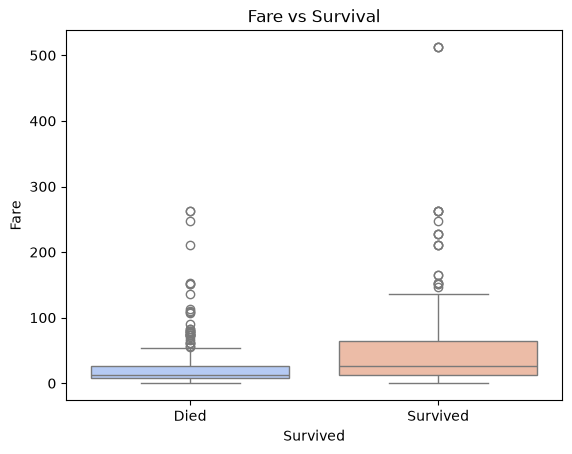

In [22]:
# 1. Box plot — spread of fare by survival
sns.boxplot(x='Survived', y='Fare', data=ndata, palette='coolwarm')
plt.title('Fare vs Survival')
plt.xticks([0, 1], ['Died', 'Survived'])
plt.show()



the people who paid more as we see the mean, Median, four quartile of fare is higher in survived boxplot than died 

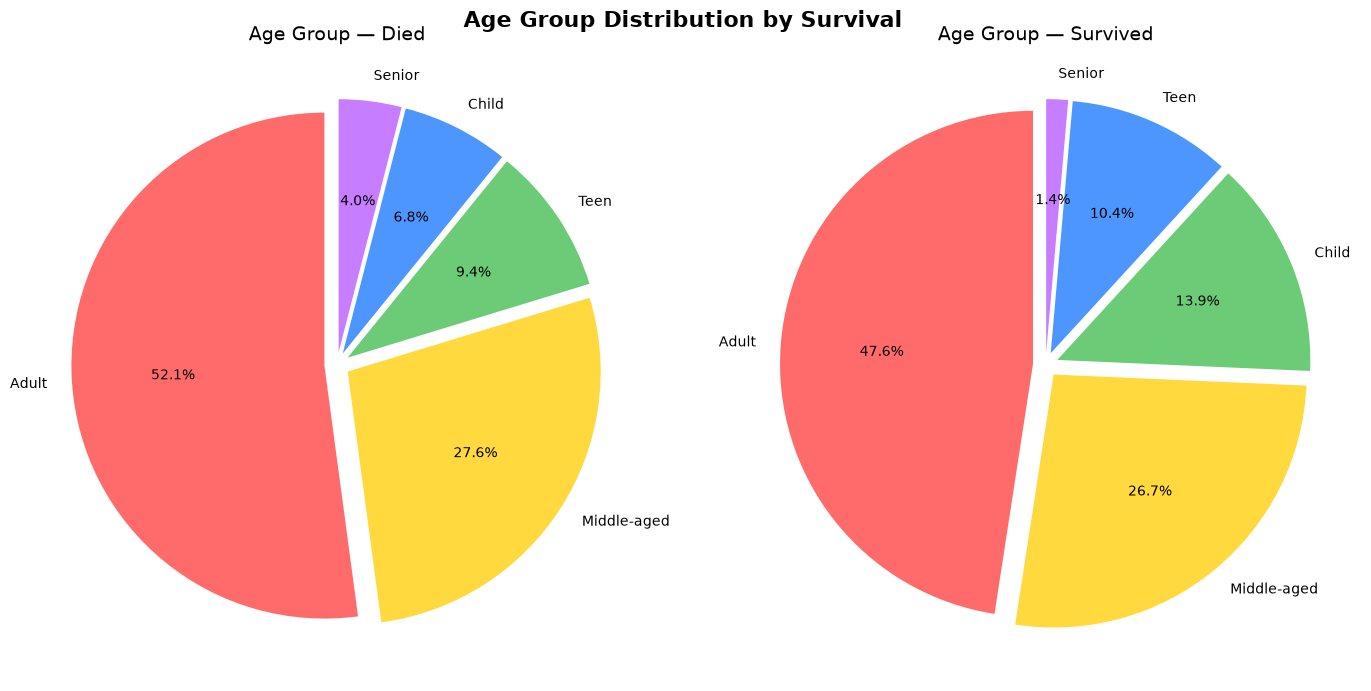

In [23]:
# Create age groups
ndata['AgeGroup'] = pd.cut(ndata['Age'],
                            bins=[0, 12, 18, 35, 60, 100],
                            labels=['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior'])

colors = ['#ff6b6b', '#ffd93d', '#6bcb77', '#4d96ff', '#c77dff']

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Pie for Died (Survived == 0)
died = ndata[ndata['Survived'] == 0]['AgeGroup'].value_counts()
axes[0].pie(died, labels=died.index, autopct='%1.1f%%',
            colors=colors, startangle=90, explode=[0.05]*len(died))
axes[0].set_title('Age Group — Died', fontsize=14)

# Pie for Survived (Survived == 1)
survived = ndata[ndata['Survived'] == 1]['AgeGroup'].value_counts()
axes[1].pie(survived, labels=survived.index, autopct='%1.1f%%',
            colors=colors, startangle=90, explode=[0.05]*len(survived))
axes[1].set_title('Age Group — Survived', fontsize=14)

plt.suptitle('Age Group Distribution by Survival', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [24]:
# the percentage are equal between the survived and died passengers in each age group.
# The pie charts show the distribution of age groups for both categories, allowing us to see which age groups had higher survival rates.
# thats means at the accident time, three people were distributed in different places

In [25]:
# the results is the people who have seats in class 1 and 2 got higher survival rates, while those in class 3 had lower survival rates. 
# This indicates that passengers in higher classes had better access to lifeboats and were prioritized during the evacuation process,
# leading to a higher chance of survival.

# Data Preprocessing

In [26]:
ndata= data.copy()

In [27]:


# ── Drop useless columns ─────────────────────────────────────
ndata.drop(columns=['PassengerId', 'Ticket'], inplace=True)

# ── Label Encoding — Sex (binary) ───────────────────────────
le = LabelEncoder()
ndata['Sex'] = le.fit_transform(ndata['Sex'])
# male → 1 , female → 0

# ── One Hot Encoding — Embarked (3 categories) ───────────────
ndata = pd.get_dummies(ndata, columns=['Embarked'], drop_first=True)
# Creates: Embarked_Q, Embarked_S  (C is the dropped reference)

# ── Preview ──────────────────────────────────────────────────
print(ndata.head())
print(ndata.dtypes)

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_Q  Embarked_S
0         0       3    1  22.0      1      0   7.2500       False        True
1         1       1    0  38.0      1      0  71.2833       False       False
2         1       3    0  26.0      0      0   7.9250       False        True
3         1       1    0  35.0      1      0  53.1000       False        True
4         0       3    1  35.0      0      0   8.0500       False        True
Survived        int64
Pclass          int64
Sex             int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked_Q       bool
Embarked_S       bool
dtype: object


# Model Building

In [ ]:



X = ndata.drop(columns=['Survived'])
y = ndata['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# ── K-Fold setup ─────────────────────────────────────────────
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# ── Models ───────────────────────────────────────────────────
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42)
    }


  Logistic Regression
  Accuracy  : 0.8020
  Precision : 0.7840
  Recall    : 0.7168


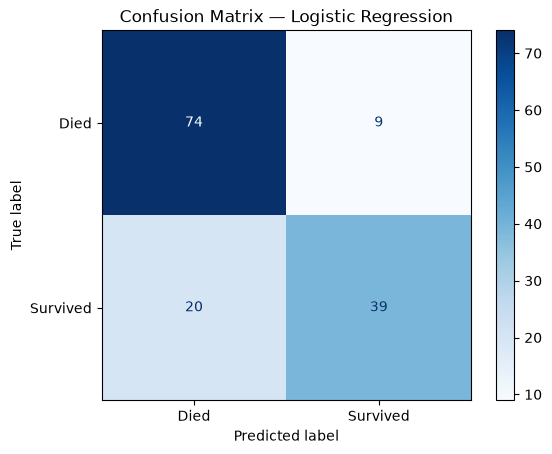


  Random Forest
  Accuracy  : 0.7823
  Precision : 0.7471
  Recall    : 0.7131


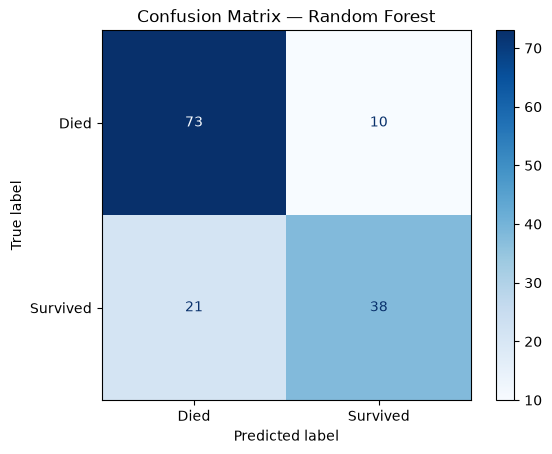


  Gradient Boosting
  Accuracy  : 0.8020
  Precision : 0.8075
  Recall    : 0.6796


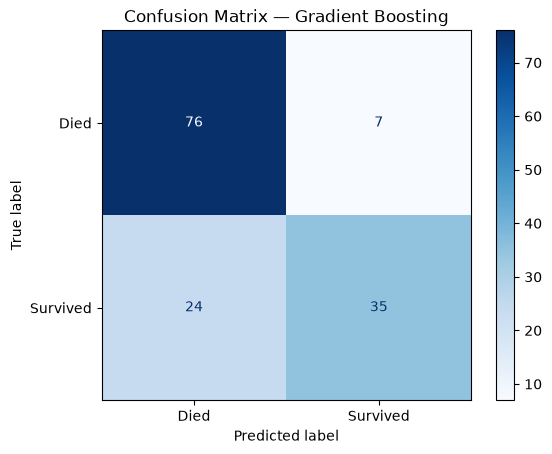

In [47]:


# ── Evaluate with K-Fold manually ────────────────────────────
for name, model in models.items():
    acc_list, prec_list, rec_list = [], [], []
    for train_idx, test_idx in kf.split(X, y):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        acc_list.append(accuracy_score(y_te, y_pred))
        prec_list.append(precision_score(y_te, y_pred))
        rec_list.append(recall_score(y_te, y_pred))
    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"{'='*45}")
    print(f"  Accuracy  : {np.mean(acc_list):.4f}")
    print(f"  Precision : {np.mean(prec_list):.4f}")
    print(f"  Recall    : {np.mean(rec_list):.4f}")
    # Confusion matrix on last fold
    cm = confusion_matrix(y_te, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived'])
    disp.plot(cmap='Blues')
    plt.title(f'Confusion Matrix — {name}')
    plt.show()


🔍 Tuning Logistic Regression...
  ✅ Best Params   : {'C': 0.1, 'solver': 'lbfgs'}
  ✅ Best CV Score : 0.8076

🔍 Tuning Random Forest...
  ✅ Best Params   : {'max_depth': 5, 'max_features': 'log2', 'n_estimators': 200}
  ✅ Best CV Score : 0.8160

🔍 Tuning Gradient Boosting...
  ✅ Best Params   : {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
  ✅ Best CV Score : 0.8202

  Logistic Regression (Tuned)
  Accuracy  : 0.8076
  Precision : 0.8103
  Recall    : 0.6925


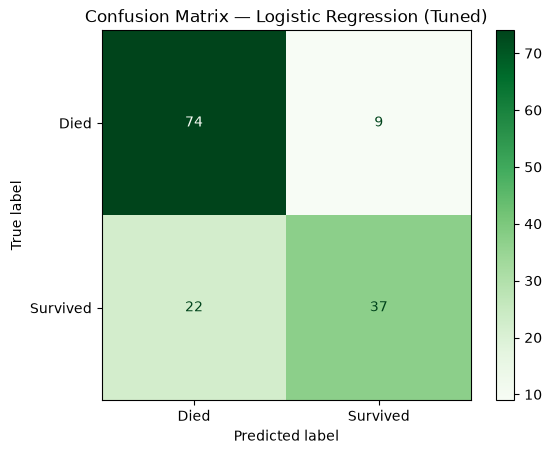


  Random Forest (Tuned)
  Accuracy  : 0.8160
  Precision : 0.8539
  Recall    : 0.6727


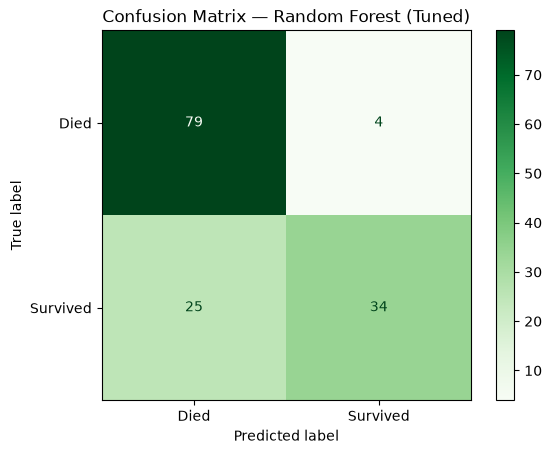


  Gradient Boosting (Tuned)
  Accuracy  : 0.8202
  Precision : 0.8956
  Recall    : 0.6425


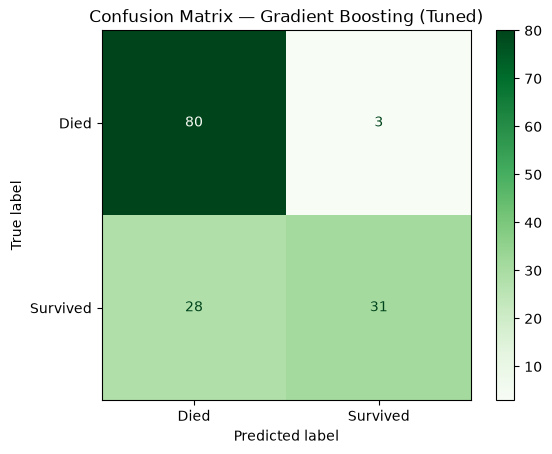

In [49]:

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ── Step 1: Param Grids ───────────────────────────────────────
param_grids = {
    'Logistic Regression': {
        'C':      [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth':    [None, 5, 10],
        'max_features': ['sqrt', 'log2']
    },
    'Gradient Boosting': {
        'n_estimators':  [100, 200],
        'max_depth':     [2, 3, 5],
        'learning_rate': [0.05, 0.1, 0.2]
    }
}

base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42)
}

# ── Step 2: GridSearch → find best params ────────────────────
best_models = {}

for name in base_models:
    print(f"\n🔍 Tuning {name}...")
    gs = GridSearchCV(
        base_models[name],
        param_grids[name],
        cv=kf,
        scoring='accuracy',
        n_jobs=-1
    )
    gs.fit(X, y)
    best_models[name] = gs.best_estimator_
    print(f"  ✅ Best Params   : {gs.best_params_}")
    print(f"  ✅ Best CV Score : {gs.best_score_:.4f}")

# ── Step 3: Evaluate tuned models with K-Fold ────────────────
for name, model in best_models.items():
    acc_list, prec_list, rec_list = [], [], []

    for train_idx, test_idx in kf.split(X, y):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)

        acc_list.append(accuracy_score(y_te, y_pred))
        prec_list.append(precision_score(y_te, y_pred))
        rec_list.append(recall_score(y_te, y_pred))

    print(f"\n{'='*45}")
    print(f"  {name} (Tuned)")
    print(f"{'='*45}")
    print(f"  Accuracy  : {np.mean(acc_list):.4f}")
    print(f"  Precision : {np.mean(prec_list):.4f}")
    print(f"  Recall    : {np.mean(rec_list):.4f}")

    # Confusion matrix (last fold)
    cm = confusion_matrix(y_te, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived'])
    disp.plot(cmap='Greens')
    plt.title(f'Confusion Matrix — {name} (Tuned)')
    plt.show()

In [ ]:
#the XgBoost model is a powerful machine learning algorithm that is widely used for classification and regression tasks. 
# It is an implementation of gradient boosting that is designed to be highly efficient, flexible, and portable. 
# it has higher performance and speed and advanced capabilities. than random forest.

# the Precision  of random forest is higher than XgBoost, but the Recall of XgBoost is higher than random forest.
# in my opinion the EDA does not provide enough information to determine which model is better.
#and the feature engineering are not enough visualize insight information from the datasets,
# so the most ideal extracted from the EDA is the nearest people emergency doors where the most likely to survive,
# # and the people who have seats in class 1 and 2 got higher survival rates,
# while those in class 3 had lower survival rates.
# Note : i did not use imputation 